In [2]:
import pandas as pd

file_path = r"J:\python\Codesoft_Data _Analysis/Online Retail.xlsx"

df = pd.read_excel(file_path)

print(df.shape)
display(df.head())

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. View all column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check column data types
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# 5. Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 6. View basic statistical information
display(df.describe(include="all").T)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Number of duplicate rows: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Calculate missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary)


,Missing Values,Missing Percentage
InvoiceNo,0,0.0
StockCode,0,0.0
Description,0,0.0
Quantity,0,0.0
InvoiceDate,0,0.0
UnitPrice,0,0.0
CustomerID,0,0.0
Country,0,0.0


In [11]:
# Keep an original copy
df_original = df.copy()

# Remove rows without CustomerID
df = df.dropna(subset=["CustomerID"]).copy()

print("Shape before cleaning:", df_original.shape)
print("Shape after removing missing CustomerID:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum())

Shape before cleaning: (401604, 8)
Shape after removing missing CustomerID: (401604, 8)

Missing values after cleaning:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [12]:
# Check duplicate records
print("Duplicate rows before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the updated dataset
print("Dataset shape after removing duplicates:", df.shape)
print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 0
Dataset shape after removing duplicates: (401604, 8)
Duplicate rows after cleaning: 0


In [13]:
# Check negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Check zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Check zero or negative prices
print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

# Check cancelled invoices
print(
    "Cancelled invoices:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

Negative quantities: 8872
Zero quantities: 0
Zero or negative prices: 40
Cancelled invoices: 8872


In [14]:
# Create a separate dataset for sales analysis
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

print("Rows before sales filtering:", len(df))
print("Rows after sales filtering:", len(sales_df))
print("Negative quantities remaining:", (sales_df["Quantity"] < 0).sum())
print("Invalid prices remaining:", (sales_df["UnitPrice"] <= 0).sum())

Rows before sales filtering: 401604
Rows after sales filtering: 392692
Negative quantities remaining: 0
Invalid prices remaining: 0


In [15]:
# Calculate revenue for each transaction line
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Total sales revenue:", round(sales_df["Revenue"].sum(), 2))
display(sales_df.head())

Total sales revenue: 8887208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [16]:
# Top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

,Description,Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,142264.75
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10
3,JUMBO BAG RED RETROSPOT,85040.54
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
5,POSTAGE,77803.96
6,PARTY BUNTING,68785.23
7,ASSORTED COLOUR BIRD ORNAMENT,56413.03
8,Manual,53419.93
9,RABBIT NIGHT LIGHT,51251.24


In [17]:
# Top 10 countries by revenue
top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_countries)

,Country,Revenue
0,United Kingdom,7285024.644
1,Netherlands,285446.340
2,EIRE,265262.460
3,Germany,228678.400
4,France,208934.310
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38367.830


In [18]:
# Extract year and month from InvoiceDate
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

display(monthly_sales)

,YearMonth,Revenue
0,2010-12,570422.730
1,2011-01,568101.310
2,2011-02,446084.920
3,2011-03,594081.760
4,2011-04,468374.331
5,2011-05,677355.150
6,2011-06,660046.050
7,2011-07,598962.901
8,2011-08,644051.040
9,2011-09,950690.202


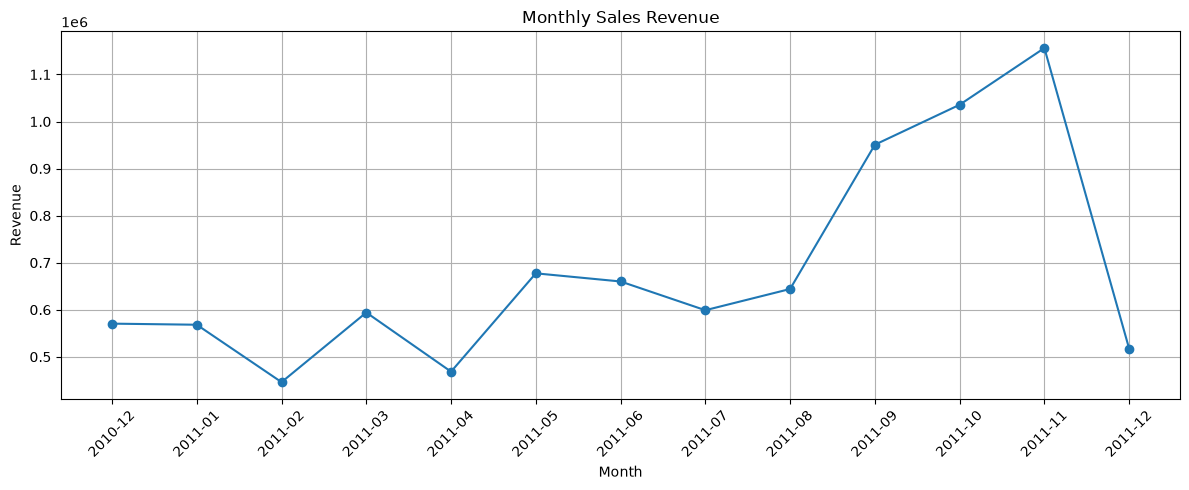

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_sales.png", dpi=300, bbox_inches="tight")
plt.show()


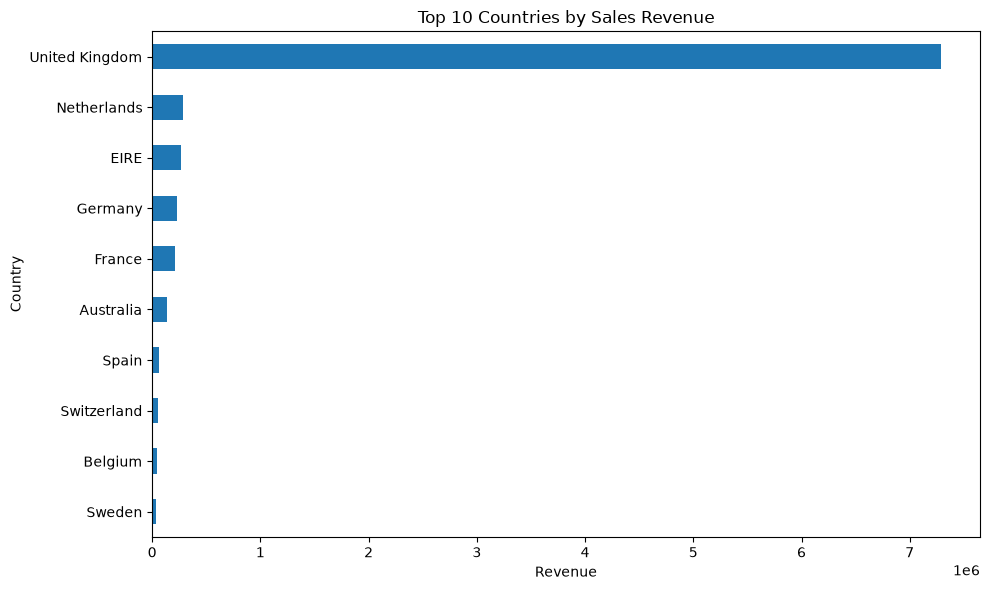

In [22]:
top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("top_10_countries.png", dpi=300, bbox_inches="tight")
plt.show()

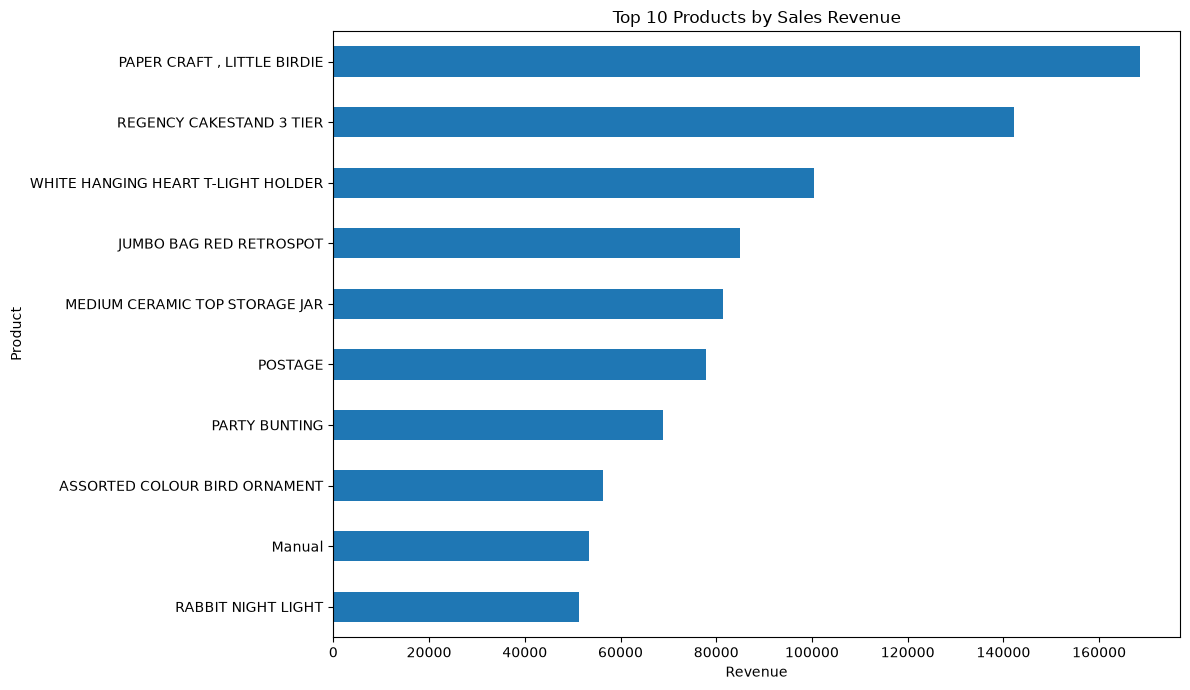

In [23]:
# Find the top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
# Save the cleaned sales data
sales_df.to_csv("Online_Retail_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
print("Total transactions:", sales_df["InvoiceNo"].nunique())
print("Total products sold:", sales_df["Quantity"].sum())
print("Total revenue:", round(sales_df["Revenue"].sum(), 2))
print("Number of countries:", sales_df["Country"].nunique())
print("Number of customers:", sales_df["CustomerID"].nunique())

Total transactions: 18532
Total products sold: 5152002
Total revenue: 8887208.89
Number of countries: 37
Number of customers: 4338


In [26]:
readme_text = """# Online Retail Data Analysis

## Project Overview
This project analyzes online retail transactions using Python to understand sales performance, product revenue, and monthly sales trends.

## Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Data Cleaning
- Checked missing values and data types.
- Removed rows with missing CustomerID.
- Removed duplicate records.
- Filtered non-positive quantities and prices for sales analysis.
- Calculated revenue using Quantity multiplied by UnitPrice.

## Key Results
- Sales transactions: 18,532
- Total quantity sold: 5,152,002
- Total revenue: 8,887,208.89
- Countries represented: 37
- Unique customers: 4,338

## Visualizations
1. Monthly Sales Revenue
2. Top 10 Countries by Sales Revenue
3. Top 10 Products by Sales Revenue

## Conclusion
This project demonstrates data cleaning, exploratory data analysis, and visualization using Python.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_text)

print("README.md created successfully!")

README.md created successfully!


In [24]:
sales_df.to_csv(
    "Online_Retail_Cleaned.csv.gz",
    index=False,
    compression="gzip"
)

print("Compressed CSV created successfully!")

Compressed CSV created successfully!


In [27]:
sales_df.to_csv(
    "Online_Retail_Cleaned.csv.gz",
    index=False,
    compression="gzip"
)

print("Compressed CSV created successfully!")



Compressed CSV created successfully!


In [28]:
print("Dataset available:", "sales_df" in globals())

if "sales_df" in globals():
    print("Dataset shape:", sales_df.shape)
    print("\nColumns:")
    print(sales_df.columns.tolist())
else:
    print("The dataset is not loaded in memory.")

Dataset available: True
Dataset shape: (392692, 10)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'YearMonth']


In [29]:
# Descriptive statistics for numerical columns
display(sales_df.describe().T)

,count,mean,min,25%,50%,75%,max,std
Quantity,392692.0,13.119702,1.0,2.0,6.0,12.0,80995.0,180.492832
InvoiceDate,392692,2011-07-10 19:13:07.771892,2010-12-01 08:26:00,2011-04-07 11:12:00,2011-07-31 12:02:00,2011-10-20 12:53:00,2011-12-09 12:50:00,NaN
UnitPrice,392692.0,3.125914,0.001,1.25,1.95,3.75,8142.75,22.241836
CustomerID,392692.0,15287.843865,12346.0,13955.0,15150.0,16791.0,18287.0,1713.539549
Revenue,392692.0,22.6315,0.001,4.95,12.45,19.8,168469.6,311.099224


In [30]:

# Check unusually high quantities and prices

print("Records with Quantity above 100:")
display(
    sales_df[sales_df["Quantity"] > 100]
    .sort_values("Quantity", ascending=False)
    [["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]]
    .head(10)
)

print("\nRecords with UnitPrice above 100:")
display(
    sales_df[sales_df["UnitPrice"] > 100]
    .sort_values("UnitPrice", ascending=False)
    [["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]]
    .head(10)
)


Records with Quantity above 100:


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
206121,554868,SMALL POPCORN HOLDER,4300,0.72,3096.00
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92
270885,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
433788,573995,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00
4945,536830,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40



Records with UnitPrice above 100:


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
173382,551697,POSTAGE,1,8142.75,8142.75
422351,573077,Manual,1,4161.06,4161.06
422376,573080,Manual,1,4161.06,4161.06
406406,571751,Manual,1,3949.32,3949.32
374542,569382,Manual,1,3155.95,3155.95
297438,562946,Manual,1,2500.00,2500.00
144826,548813,Manual,1,2382.92,2382.92
406407,571751,Manual,1,2118.74,2118.74
144829,548820,Manual,1,2053.07,2053.07
343000,566927,Manual,1,2033.10,2033.10


In [31]:

# Count unusually high values for EDA

print("Records with Quantity above 100:",
      (sales_df["Quantity"] > 100).sum())

print("Records with UnitPrice above 100:",
      (sales_df["UnitPrice"] > 100).sum())

print("Records with UnitPrice above 1000:",
      (sales_df["UnitPrice"] > 1000).sum())

print("Records with Description 'Manual':",
      sales_df["Description"].str.strip().str.lower().eq("manual").sum())


Records with Quantity above 100: 4657
Records with UnitPrice above 100: 189
Records with UnitPrice above 1000: 21
Records with Description 'Manual': 279


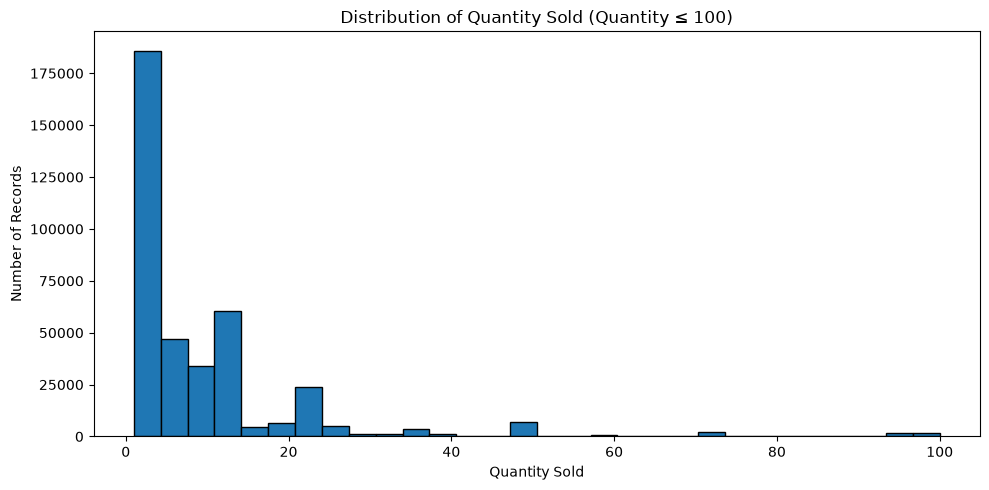

In [32]:

import matplotlib.pyplot as plt

quantity_data = sales_df.loc[
    sales_df["Quantity"] <= 100, "Quantity"
]

plt.figure(figsize=(10, 5))
plt.hist(quantity_data, bins=30, edgecolor="black")

plt.title("Distribution of Quantity Sold (Quantity ≤ 100)")
plt.xlabel("Quantity Sold")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig("quantity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


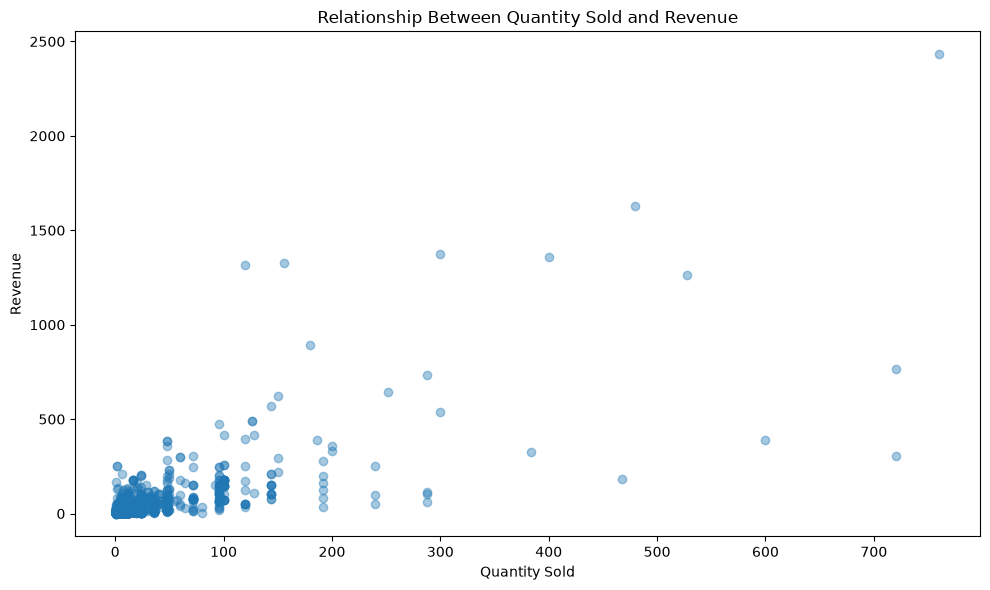

In [33]:

import matplotlib.pyplot as plt

# Use a sample to make the scatter plot easier to read
sample_df = sales_df.sample(
    n=min(5000, len(sales_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))
plt.scatter(
    sample_df["Quantity"],
    sample_df["Revenue"],
    alpha=0.4
)

plt.title("Relationship Between Quantity Sold and Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue")
plt.tight_layout()

plt.savefig("quantity_vs_revenue.png", dpi=300, bbox_inches="tight")
plt.show()


In [34]:

# Monthly revenue analysis

monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

print("Monthly Revenue:")
display(monthly_revenue.to_frame())

print("\nMonth with highest revenue:")
print(monthly_revenue.idxmax())

print("Highest monthly revenue:")
print(round(monthly_revenue.max(), 2))

print("\nMonth with lowest revenue:")
print(monthly_revenue.idxmin())

print("Lowest monthly revenue:")
print(round(monthly_revenue.min(), 2))


Monthly Revenue:


,Revenue
YearMonth,
2010-12,570422.730
2011-01,568101.310
2011-02,446084.920
2011-03,594081.760
2011-04,468374.331
2011-05,677355.150
2011-06,660046.050
2011-07,598962.901
2011-08,644051.040



Month with highest revenue:
2011-11
Highest monthly revenue:
1156205.61

Month with lowest revenue:
2011-02
Lowest monthly revenue:
446084.92


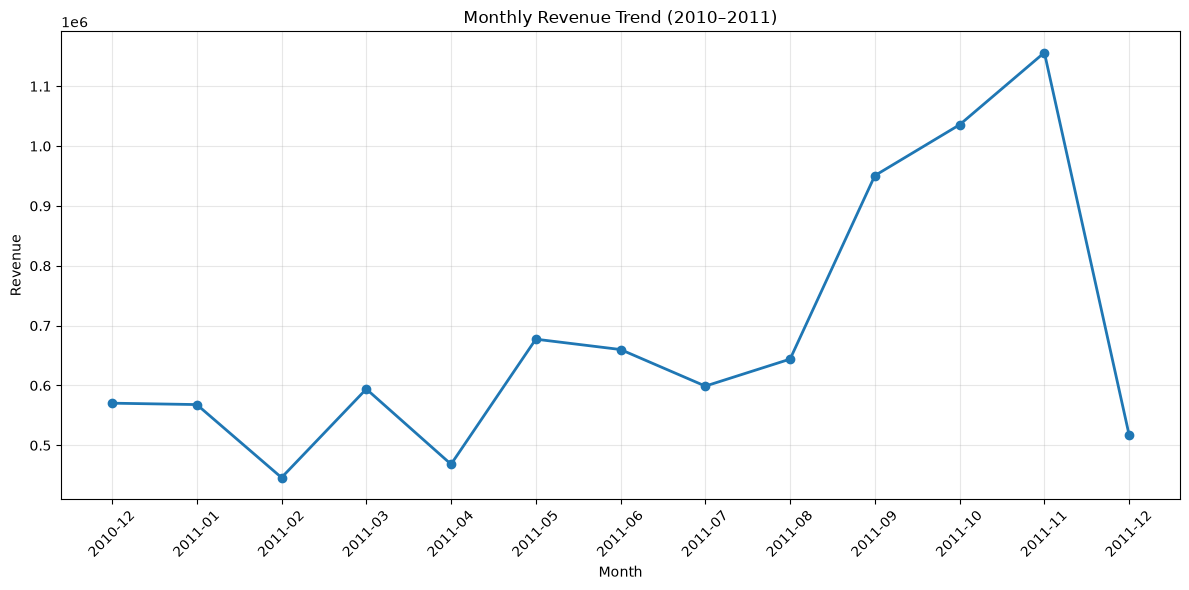

In [35]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (2010–2011)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:

# Customer purchasing behavior analysis

customer_analysis = (
    sales_df.groupby("CustomerID")
    .agg(
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum")
    )
    .sort_values("TotalRevenue", ascending=False)
)

print("Top 10 customers by revenue:")
display(customer_analysis.head(10).round(2))

print("\nTotal unique customers:", customer_analysis.shape[0])

print("\nAverage revenue per customer:",
      round(customer_analysis["TotalRevenue"].mean(), 2))

print("\nHighest customer revenue:",
      round(customer_analysis["TotalRevenue"].max(), 2))


Top 10 customers by revenue:


,TotalOrders,TotalQuantity,TotalRevenue
CustomerID,,,
14646.0,73,196915,280206.02
18102.0,60,64124,259657.30
17450.0,46,69973,194390.79
16446.0,2,80997,168472.50
14911.0,201,80240,143711.17
12415.0,21,77374,124914.53
14156.0,55,57768,117210.08
17511.0,31,64549,91062.38
16029.0,63,40108,80850.84



Total unique customers: 4338

Average revenue per customer: 2048.69

Highest customer revenue: 280206.02


In [37]:

# Segment customers based on total revenue

q1 = customer_analysis["TotalRevenue"].quantile(1/3)
q2 = customer_analysis["TotalRevenue"].quantile(2/3)

def segment_customer(revenue):
    if revenue >= q2:
        return "High Value"
    elif revenue >= q1:
        return "Medium Value"
    else:
        return "Low Value"

customer_analysis["CustomerSegment"] = (
    customer_analysis["TotalRevenue"].apply(segment_customer)
)

segment_summary = (
    customer_analysis.groupby("CustomerSegment")
    .agg(
        CustomerCount=("TotalRevenue", "count"),
        TotalRevenue=("TotalRevenue", "sum"),
        AverageRevenue=("TotalRevenue", "mean")
    )
    .round(2)
)

print("Customer Segment Summary:")
display(segment_summary)

print("\nRevenue thresholds:")
print("Low/Medium threshold:", round(q1, 2))
print("Medium/High threshold:", round(q2, 2))


Customer Segment Summary:


,CustomerCount,TotalRevenue,AverageRevenue
CustomerSegment,,,
High Value,1446,7545720.93,5218.34
Low Value,1446,317006.67,219.23
Medium Value,1446,1024481.29,708.49



Revenue thresholds:
Low/Medium threshold: 388.06
Medium/High threshold: 1191.86


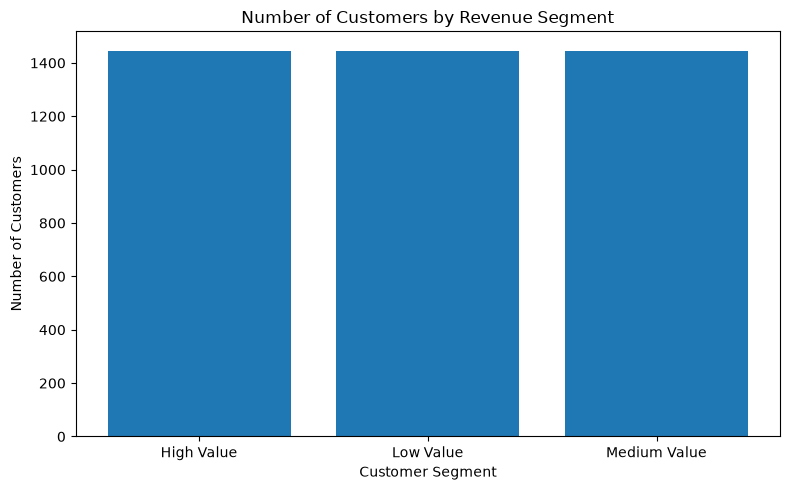

In [38]:

import matplotlib.pyplot as plt

# Customer count by segment
segment_counts = segment_summary["CustomerCount"]

plt.figure(figsize=(8, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("Number of Customers by Revenue Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


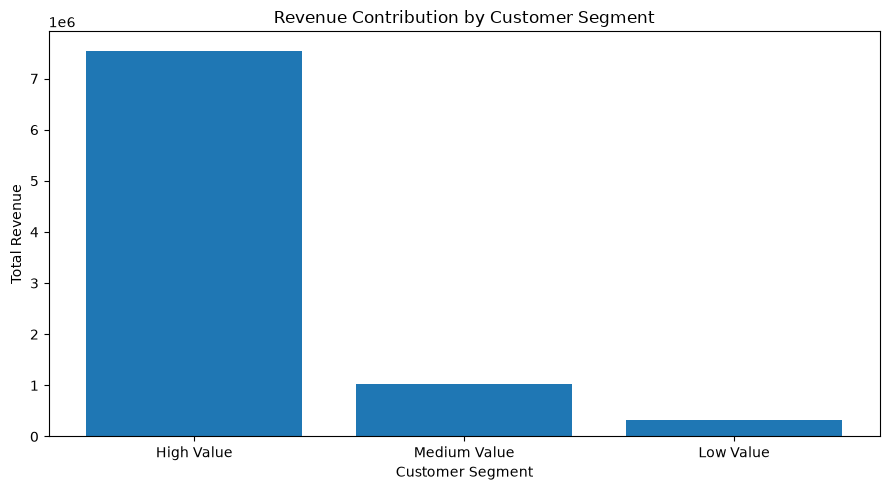

In [39]:

import matplotlib.pyplot as plt

# Revenue contributed by each customer segment
segment_revenue = segment_summary["TotalRevenue"].sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(segment_revenue.index, segment_revenue.values)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.savefig(
    "customer_segment_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [40]:

## Customer Data Analysis

### Objective
Analyze customer purchasing behavior and identify valuable customer groups using the Online Retail dataset.

### Key Findings
- The cleaned sales dataset contains 4,338 unique customers.
- The average revenue per customer is 2,048.69.
- Customer 14646 generated the highest revenue, totaling 280,206.02.
- Customers were segmented into High Value, Medium Value, and Low Value groups using revenue quantiles.
- Each segment contains 1,446 customers.

### Customer Segment Results

| Segment | Customers | Total Revenue | Average Revenue |
|---|---:|---:|---:|
| High Value | 1,446 | 7,545,720.93 | 5,218.34 |
| Medium Value | 1,446 | 1,024,481.29 | 708.49 |
| Low Value | 1,446 | 317,006.67 | 219.23 |

### Marketing Recommendations
1. High Value: Offer loyalty rewards and personalized product recommendations.
2. Medium Value: Use targeted promotions to encourage repeat purchases.
3. Low Value: Test affordable offers and follow-up campaigns to increase engagement.

### Conclusion
Customer revenue analysis reveals substantial differences in purchasing value. Revenue-based segmentation can help businesses prioritize retention efforts and develop targeted marketing strategies.


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2735103172.py, line 18)